# 05 · Fun facts y conclusiones generales

**Responsable:** Integrante E · **Plan:** ver `PLAN.md`

Hallazgos complementarios y cierre del proyecto.

## Preparación

In [1]:
from pathlib import Path
import sys

# Busca la raíz del repo (la carpeta que contiene src/) sin importar desde dónde se abra el notebook.
RAIZ = next(p for p in [Path.cwd(), *Path.cwd().parents] if (p / "src").is_dir())
sys.path.insert(0, str(RAIZ))

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns

sns.set_theme(style="whitegrid")  # estilo común para todas las figuras del proyecto

from src import contratos, rutas
from src import limpieza, polarizacion

## Datos

In [2]:
movies, ratings = limpieza.datos_limpios()
contratos.verificar_esquema(movies, "movies")
contratos.verificar_esquema(ratings, "ratings")
print(movies.shape, ratings.shape)

stats = polarizacion.stats_peliculas(ratings, movies, min_n=20)
contratos.verificar_esquema(stats, "stats_peliculas")

(9742, 23) (100836, 5)


## 1. Mejores y peores películas de todos los tiempos (n ≥ 20)

In [3]:
# verificar que stats ya tiene solo las de >=20 reviews
print(f'(Mínimo de reviews: {stats.n.min()})')

def worst_best_n_movies(mov_stats: pd.DataFrame = stats,
                        n: int = 10,
                        worst_best: str = 'best',
                        by: str = 'media') -> pd.DataFrame:
    """
    Devuelve las n películas con el mejor (worst_best = 'best') o peor (worst_best = 'worst')
    promedio (si by = 'media', por otra métrica si el parámetro cambia) en sus reviews (se aplica a la tabla stats).
    Por default: las 10 mejores por promedio de puntuación.
    """
    # validar cantidad de filas, parámetro worst_best, y columna de by
    if n > len(mov_stats):
        print('n excede la cantidad de películas consideradas')
        return pd.DataFrame(columns=mov_stats.columns)
    if not worst_best in ['worst','best']:
        print('Valor no válido para worst_best')
        return pd.DataFrame(columns=mov_stats.columns)
    if not by in mov_stats.columns:
        print(f"La columna '{by}' no existe.")
        return pd.DataFrame(columns=mov_stats.columns)

    # worst -> orden ascendente, best-> orden descendente
    asc = worst_best == 'worst'
    selected = mov_stats.copy()\
                    .sort_values(by=by, ascending=asc)\
                    .reset_index(drop=True).iloc[:n]
    
    return selected

print('='*50)
print('Las 10 pelis con *MEJORES* reviews (todos los años):')
print(worst_best_n_movies()\
    .transform({
        'title': lambda x:x, #str(x).split('(')[0].strip(),
        'movieId': lambda x:x,
        'media': lambda x: f'★{x:.2f}',
    })
)
print('='*50)
print('Las 10 pelis con *PEORES* reviews (todos los años):')
print(worst_best_n_movies(worst_best='worst')\
    .transform({
        'title': lambda x:x , #str(x).split('(')[0].strip(),
        'movieId': lambda x:x,
        'media': lambda x: f'★{x:.2f}',
    })
)

# guardar tablas (con valores numéricos, sin formato)
cols = ['movieId', 'title', 'anio', 'n', 'media']
rutas.guardar_tabla(worst_best_n_movies()[cols], '05_mejores_10')
rutas.guardar_tabla(worst_best_n_movies(worst_best='worst')[cols], '05_peores_10')

(Mínimo de reviews: 20)
Las 10 pelis con *MEJORES* reviews (todos los años):
                                           title movieId  media
0               Streetcar Named Desire, A (1951)    1104  ★4.47
1               Shawshank Redemption, The (1994)     318  ★4.43
2  Sunset Blvd. (a.k.a. Sunset Boulevard) (1950)     922  ★4.33
3                 Philadelphia Story, The (1940)     898  ★4.31
4                      Lawrence of Arabia (1962)    1204  ★4.30
5               In the Name of the Father (1993)     475  ★4.30
6                             Hoop Dreams (1994)     246  ★4.29
7                          Godfather, The (1972)     858  ★4.29
8                        Harold and Maude (1971)    1235  ★4.29
9                                   Logan (2017)  168252  ★4.28
Las 10 pelis con *PEORES* reviews (todos los años):
                                    title movieId  media
0                         Anaconda (1997)    1499  ★1.93
1                         Godzilla (1998)    1882  ★1

WindowsPath('C:/Users/Andres Sanchez/OneDrive - Multilog Internacional S.A de C.V/Documents/Scripts/movielens-proyecto-integrador/results/tables/05_peores_10.csv')

## 2. Mejores y peores por década de estreno

In [4]:
# agregamos la columna de década
stats['decada'] = (stats['anio'] // 10) *10

# filtro para las que sí tienen década
tiene_decada = stats.decada.notna()
print(f'({len(stats[~tiene_decada])} películas no tienen información sobre su década de estreno)')

stats_con_decada = stats.copy()[tiene_decada]

# obtenemos las décadas que abarca el dataset, ordenadas cronológicamente
decadas = sorted(stats_con_decada['decada'].unique())

# usamos la función previamente definida para obtener la mejor y peor por década
print('='*50)
filas = []  # una fila por década, para guardar la tabla
for d in decadas:

    stats_d = stats_con_decada[
        stats_con_decada['decada'] == d
    ]

    best_d = worst_best_n_movies(stats_d,1)
    worst_d = worst_best_n_movies(stats_d,1, worst_best='worst')
    filas.append({'decada': d, 'n_peliculas': len(stats_d),
                  'mejor': best_d.title.iloc[0], 'media_mejor': best_d.media.iloc[0],
                  'peor': worst_d.title.iloc[0], 'media_peor': worst_d.media.iloc[0]})

    print(f'** {d} **   [{len(stats_d)} películas]')
    print('='*50)

    print(f'Mejor peli')
    print(' ->',
        best_d.title.iloc[0],
        f'(★{best_d.media.iloc[0]:.2f})'
    )

    print(f'Peor peli')
    print(' ->',
        worst_d.title.iloc[0],
        f'(★{worst_d.media.iloc[0]:.2f})'
    )

    print('='*50)

rutas.guardar_tabla(pd.DataFrame(filas), '05_mejor_peor_por_decada')

(0 películas no tienen información sobre su década de estreno)
** 1920 **   [1 películas]
Mejor peli
 -> Metropolis (1927) (★3.86)
Peor peli
 -> Metropolis (1927) (★3.86)
** 1930 **   [6 películas]
Mejor peli
 -> Wizard of Oz, The (1939) (★3.88)
Peor peli
 -> Snow White and the Seven Dwarfs (1937) (★3.62)
** 1940 **   [12 películas]
Mejor peli
 -> Philadelphia Story, The (1940) (★4.31)
Peor peli
 -> Bambi (1942) (★3.37)
** 1950 **   [25 películas]
Mejor peli
 -> Streetcar Named Desire, A (1951) (★4.47)
Peor peli
 -> Alice in Wonderland (1951) (★3.38)
** 1960 **   [36 películas]
Mejor peli
 -> Lawrence of Arabia (1962) (★4.30)
Peor peli
 -> 101 Dalmatians (One Hundred and One Dalmatians) (1961) (★3.43)
** 1970 **   [59 películas]
Mejor peli
 -> Godfather, The (1972) (★4.29)
Peor peli
 -> Star Trek: The Motion Picture (1979) (★3.04)
** 1980 **   [169 películas]
Mejor peli
 -> Princess Bride, The (1987) (★4.23)
Peor peli
 -> Superman III (1983) (★2.25)
** 1990 **   [474 películas]
Mejor p

WindowsPath('C:/Users/Andres Sanchez/OneDrive - Multilog Internacional S.A de C.V/Documents/Scripts/movielens-proyecto-integrador/results/tables/05_mejor_peor_por_decada.csv')

## 3. Películas más polémicas

In [5]:
# la función de worst_best_n_movies sirve
# (con by = 'std') 

top_10_polemicas = worst_best_n_movies(
    n = 10,
    by = 'std'
)

rutas.guardar_tabla(top_10_polemicas[['movieId', 'title', 'n', 'media', 'std', 'ric']], '05_polemicas_10')

print('Top 10 Películas MÁS POLÉMICAS de todos los años (según su std)')
top_10_polemicas\
    .transform({
    'title': lambda x: str(x).split('(')[0].strip(),
    'movieId': lambda x: x,
    'media': lambda x: f'★{x:.2f}',
    'std': lambda x: f'{x:.2f}',
    'ric': lambda x: f'{x:.1f}'
})

Top 10 Películas MÁS POLÉMICAS de todos los años (según su std)


,title,movieId,media,std,ric
0,"Thin Red Line, The",2427,★3.30,1.42,2.5
1,Barb Wire,737,★2.65,1.40,1.4
2,"Blair Witch Project, The",2710,★2.80,1.37,2.5
3,Home Alone 2: Lost in New York,2953,★2.52,1.36,2.0
4,"Girl with the Dragon Tattoo, The",91658,★3.49,1.33,1.4
5,Scary Movie 3,6888,★2.27,1.31,1.5
6,Babe: Pig in the City,2384,★2.78,1.30,2.0
7,First Knight,168,★3.08,1.30,2.0
8,Midnight in the Garden of Good and Evil,1711,★3.10,1.29,2.0
9,Crocodile Dundee II,2471,★2.48,1.28,2.0


## 4. Géneros con más y menos calificaciones

In [6]:
# reviews por películas
rev_por_pelicula = ratings.groupby('movieId').size()

movies['n_reviews'] = movies.movieId.map(rev_por_pelicula)\
                            .fillna(0).astype(int)

# reviews por género
from src.contratos import GENEROS
assert all(g in movies.columns for g in GENEROS),\
    'La tabla movies no contiene todos los géneros.'

rev_por_genero = pd.DataFrame(movies)[GENEROS]\
    .mul(movies.n_reviews, axis=0)\
    .sum()\
    .sort_values(ascending=False)

print('='*50)
print('Géneros por número de ratings:')
print('='*50)
rev_por_genero

Géneros por número de ratings:


Drama          41928
Comedy         39053
Action         30635
Thriller       26452
Adventure      24161
Romance        18124
Sci-Fi         17243
Crime          16681
Fantasy        11834
Children        9208
Mystery         7674
Horror          7291
Animation       6988
War             4859
Musical         4138
Western         1930
Documentary     1219
Film-Noir        870
dtype: int64

## 5. Actividad de calificación en el tiempo

(Última review registrada en:2018-09-24 14:27:30+00:00)


WindowsPath('C:/Users/Andres Sanchez/OneDrive - Multilog Internacional S.A de C.V/Documents/Scripts/movielens-proyecto-integrador/results/figures/05_ratings_por_anio.png')

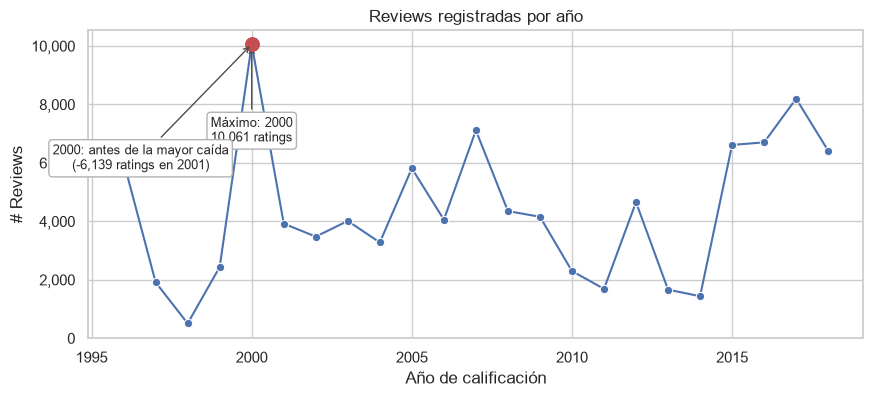

In [7]:
from matplotlib.ticker import StrMethodFormatter

print(f'(Última review registrada en:{ratings.fecha.max()})')

rev_por_anio = ratings.groupby('anio_rating').size()
# incluir años sin ratings como 0, para que la línea no los salte
rev_por_anio = rev_por_anio.reindex(
    range(rev_por_anio.index.min(),
          rev_por_anio.index.max() + 1), 
          fill_value=0
)

#------------------------------------------------------------

# queremos que la gráfica muestre dos puntos de interés:
# 1. El año con mayor actividad
# 2. El punto de inflexión negativa más grande 
# (la caída más grande en actividad)

anio_max = rev_por_anio.idxmax()

# para la caída consideramos únicamente hasta el penúltimo año (el último está incompleto)
completos = rev_por_anio.loc[ratings.fecha.min().year + 1 : ratings.fecha.max().year - 1]
cambio = completos.diff()             # cambio vs. el año anterior
anio_caida = cambio.idxmin()          # año con la caída más fuerte
anio_antes_caida = anio_caida - 1     # último año antes de esa caída

#creamos la figura vacía con las medidas
scaling = 2
fig, ax = plt.subplots(figsize=(5*scaling, 2*scaling))

# creamos la función que marca los puntos de interés en la gráfica

def marcar(anio, texto, dx=0, dy=-70):
    """Resalta el punto de `anio` y le pone una etiqueta con flecha."""
    y = rev_por_anio[anio]
    ax.scatter(anio, y, s=90, color='C3', zorder=3)
    ax.annotate(
        texto, xy=(anio, y),
        xytext=(dx, dy), textcoords='offset points',   # desplazamiento en puntos, no en datos
        ha='center', fontsize=9,
        bbox=dict(boxstyle='round,pad=0.3', fc='white', ec='0.7'),
        arrowprops=dict(arrowstyle='->', color='0.3'),
    )

# ahora sí graficamos los datos

sns.lineplot(
    x = rev_por_anio.index,
    y = rev_por_anio.values,
    marker = 'o',
    ax = ax
)

ax.set(
    title = 'Reviews registradas por año',
    xlabel = 'Año de calificación',
    ylabel = '# Reviews',
    ylim = (0,None), # para que el eje Y empiece en 0
)
ax.yaxis.set_major_formatter(StrMethodFormatter('{x:,.0f}'))  # 12,345 en vez de 12345

marcar(anio_max, f'Máximo: {anio_max}\n{rev_por_anio[anio_max]:,} ratings')
marcar(anio_antes_caida,
       f'{anio_antes_caida}: antes de la mayor caída\n'
       f'({cambio[anio_caida]:+,.0f} ratings en {anio_caida})',
       dx=-80, dy=-90)

rutas.guardar_figura(fig, "05_ratings_por_anio")

> **Interpretación**
> - *Qué muestra:* …
> - *Por qué es relevante:* …
> - *Limitaciones:* …

## 6. Conclusiones generales

- **Pregunta 1:** …
- **Pregunta 2a:** …
- **Pregunta 2b:** …

### Qué no podemos afirmar

- …

### Líneas futuras

- …